In [1]:

# This setup is only needed to run and test my notebook independently.
# It can be skipped when integrating into report.ipynb,
# since the imports and analyzer are already initialized there.

import sys
from pathlib import Path
import pandas as pd

sys.path.append("..")

from src.ecommerce import EcommerceAnalyzer

analyzer = EcommerceAnalyzer()
column = "revenue"



## Fråga 6 – Finns det några avvikelser?

Vi börjar med att undersöka den statistiska fördelningen av ordervärden genom att beräkna medelvärde, median, standardavvikelse, kvartiler samt minimi- och maximivärden.

Därefter använder vi **IQR-metoden (Interquartile Range)** för att identifiera ovanligt höga eller låga ordervärden. Gränserna beräknas som Q1 − 1,5 × IQR och Q3 + 1,5 × IQR.

Resultatet visar antalet avvikande ordrar, deras procentuella andel av samtliga ordrar samt de beräknade gränsvärdena.

Avvikande värden behöver inte vara felaktiga, men kan vara intressanta att undersöka vidare.

In [2]:

# The IQR method can identify outliers in any numeric column.
# We chose "revenue" for this analysis, but the column can be changed to analyze other numeric values.
column = "revenue"
outliers, lower_bound, upper_bound = analyzer.identify_outliers(column)

count = len(outliers)
percentage = count / len(analyzer.df) * 100

print(f"\nStatistisk sammanfattning för kolumnen {column}:\n")
print(analyzer.df[column].describe().round(2))

print(f"\nNedre gräns för avvikande värden: {lower_bound:.2f}")
print(f"Övre gräns för avvikande värden: {upper_bound:.2f}")

print(
    f"\nAntal avvikande ordrar baserat på {column} är: {count}. "
    f"Det motsvarar {percentage:.2f}% av totalt "
    f"{len(analyzer.df)} ordrar enligt IQR-metoden."
)



Statistisk sammanfattning för kolumnen revenue:

count    2500.00
mean     1401.11
std      1166.94
min        50.00
25%       577.96
50%      1088.69
75%      1884.75
max      9192.60
Name: revenue, dtype: float64

Nedre gräns för avvikande värden: -1382.22
Övre gräns för avvikande värden: 3844.93

Antal avvikande ordrar baserat på revenue är: 111. Det motsvarar 4.44% av totalt 2500 ordrar enligt IQR-metoden.


### Visualisering av avvikande värden

För att tydliggöra fördelningen av ordervärden används ett boxplot-diagram.

Diagrammet visar median, kvartiler och spridning samt de avvikande värden som identifierats med IQR-metoden. 


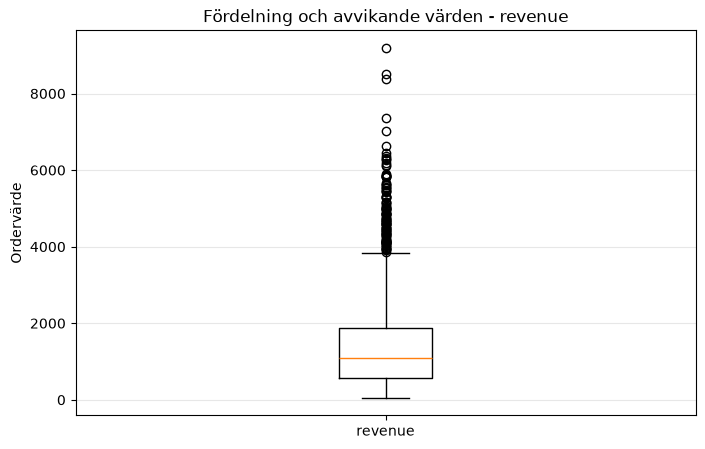

In [3]:

fig = analyzer.plot_outliers_boxplot(column)
display(fig)


### Avvikelser per produktkategori

För att undersöka om avvikande ordervärden förekommer oftare inom vissa produktkategorier beräknas andelen avvikande ordrar i förhållande till det totala antalet ordrar inom respektive kategori.

Detta gör det möjligt att jämföra kategorier med olika antal ordrar på ett mer rättvisande sätt.

Resultatet visualiseras i ett stapeldiagram som visar den procentuella andelen avvikande ordrar per produktkategori.

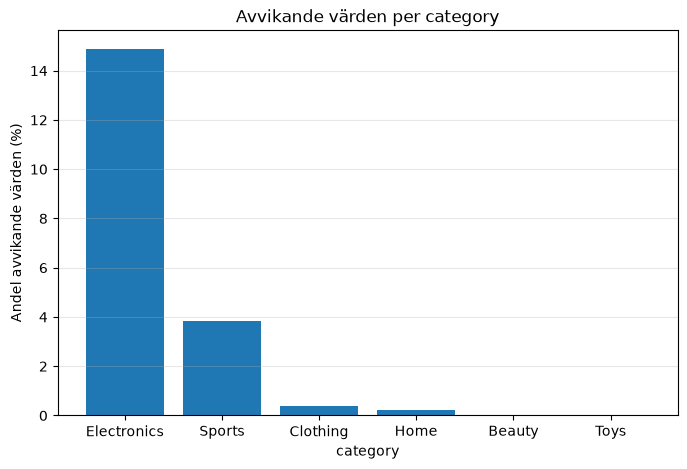

In [4]:

fig = analyzer.plot_outliers_by_group(column, "category")
display(fig)


### Resultat och slutsats

Analysen identifierade totalt **111 avvikande ordrar** enligt IQR-metoden för kolumnen `revenue`. Den övre gränsen beräknades till 3 844,93 och den nedre gränsen till −1 382,22.

Fördelningen av avvikande ordrar skiljer sig mellan produktkategorierna:

- **Electronics:** 92 avvikande ordrar (14,9 %).
- **Sports:** 16 avvikande ordrar (3,9 %).
- **Clothing:** 2 avvikande ordrar (0,4 %).
- **Home:** 1 avvikande order (0,2 %).
- **Beauty och Toys:** Inga identifierade avvikande ordrar.

Resultatet visar att elektronik har den klart högsta andelen avvikande ordervärden. De identifierade avvikelserna ligger över den övre IQR-gränsen.

Detta innebär inte nödvändigtvis att datamaterialet innehåller fel. En möjlig förklaring är att vissa produktkategorier innehåller dyrare produkter eller större beställningar.

För att avgöra orsakerna behöver de avvikande ordrarna undersökas närmare. Därför bör de inte tas bort automatiskt från datamaterialet.